In [135]:
#%pip install sqlalchemy pymysql pandas

In [136]:
from sqlalchemy import create_engine
import pandas as pd


Our database contains restaurant data collected through the POS system, which has been in use since the restaurant first opened.

In [139]:
import pandas as pd

df_article = pd.read_csv("caverna_data/article.csv")

df_caisse_journee = pd.read_csv("caverna_data/caisse_journee.csv")

df_caisse_mouvement = pd.read_csv("caverna_data/caisse_mouvement.csv")

df_caisse_mouvement_article = pd.read_csv(
    "caverna_data/caisse_mouvement_article.csv"
)

df_journee = pd.read_csv("caverna_data/journee.csv")

C:\Users\Laptop\AppData\Local\Temp\ipykernel_28264\467883521.py:7: DtypeWarning: Columns (0: date_fin_stat2) have mixed types. Specify dtype option on import or set low_memory=False.
  df_caisse_mouvement = pd.read_csv("caverna_data/caisse_mouvement.csv")
C:\Users\Laptop\AppData\Local\Temp\ipykernel_28264\467883521.py:9: DtypeWarning: Columns (0: commentaire, 1: date_debut_stat2, 2: date_fin_stat, 3: date_fin_stat2, 4: is_encaisse, 5: is_offert, 6: is_suite_end, 7: is_suite_lock, 8: nbr_statut) have mixed types. Specify dtype option on import or set low_memory=False.
  df_caisse_mouvement_article = pd.read_csv(


# Cleaning article table 

In [140]:
df_article = df_article.dropna(axis=1, how="all")

In [141]:
df_article.head()

,id,date_creation,date_maj,etablissement_id,signature,code,destination,is_disable,is_fav_caisse,is_noncaisse,is_nonmobile,is_stock,libelle,prix_vente,famille_cuisine_id
0,1,2023-08-02 17:58:38,2024-06-30 17:11:15,1,CAVERNA,11,C,b'\x01',NaN,NaN,NaN,b'\x00',PIZZA MARGHERITA J,30.0,7
1,2,2023-08-02 17:58:50,2024-06-30 17:11:55,1,CAVERNA,12,C,b'\x01',NaN,NaN,NaN,b'\x00',PIZZA AU THON J,35.0,7
2,3,2023-08-02 17:59:03,2024-06-30 17:12:31,1,CAVERNA,13,C,b'\x01',b'\x01',NaN,NaN,b'\x00',PIZZA FRUITS DE MER J,50.0,7
3,4,2023-08-02 17:59:20,2024-06-30 17:13:05,1,CAVERNA,14,C,b'\x01',NaN,NaN,NaN,b'\x00',PIZZA VIANDE HACHEE J,45.0,7
4,5,2023-08-02 17:59:35,2024-06-30 17:13:31,1,CAVERNA,15,C,b'\x01',NaN,NaN,NaN,b'\x00',PIZZA MEXICAIN J,45.0,7


In [142]:
df_article = df_article[["libelle","prix_vente","date_creation", "is_stock"]]

In [143]:
df_article = df_article[
    df_article["is_stock"] != None
]


In [144]:
df_article = df_article.rename(columns={
    'libelle': 'Article Name',
    'prix_vente': 'Price',
    'date_creation': 'Creation Date'
})

In [145]:
df_article = df_article[["Article Name","Price","Creation Date"]]
df_article["Creation Date"] = pd.to_datetime(df_article["Creation Date"]).dt.date


In [146]:
df_article.head()

,Article Name,Price,Creation Date
0,PIZZA MARGHERITA J,30.0,2023-08-02
1,PIZZA AU THON J,35.0,2023-08-02
2,PIZZA FRUITS DE MER J,50.0,2023-08-02
3,PIZZA VIANDE HACHEE J,45.0,2023-08-02
4,PIZZA MEXICAIN J,45.0,2023-08-02


The caisse_journee table contains the following columns: id, Date Open, Date Close, Sales Number, Total Amount, Amount Card, Amount Cash and Offre.

Get Only Important Columns

In [147]:
df_caisse_journee = df_caisse_journee[[
    "id","date_ouverture", "date_cloture", "nbr_vente","mtt_total", "mtt_cb", "mtt_espece", "mtt_reduction"
]]

In [148]:
df_caisse_journee = df_caisse_journee.dropna(subset=['mtt_total'])

In [149]:
df_caisse_journee.head()

,id,date_ouverture,date_cloture,nbr_vente,mtt_total,mtt_cb,mtt_espece,mtt_reduction
0,1,2023-08-02 13:15:04,2023-08-03 15:28:45,9.0,886.0,0.0,886.0,0.0
1,2,2023-08-03 15:32:01,2023-08-03 15:46:29,10.0,74.0,0.0,74.0,0.0
2,3,2023-08-03 15:46:47,2023-08-03 15:59:11,2.0,465.0,0.0,465.0,0.0
3,4,2023-08-03 15:59:11,2023-08-03 16:01:47,3.0,164.0,0.0,164.0,0.0
4,5,2023-08-03 16:02:21,2023-08-03 16:12:00,2.0,0.0,0.0,0.0,0.0


In [150]:
df_caisse_journee = df_caisse_journee.rename(columns={
    'date_ouverture': 'Date Open',
    'date_cloture': 'Date Close',
    'nbr_vente': 'Sales Number',
    'mtt_total': 'Total Amount',
    'mtt_cb': 'Amount Card',
    'mtt_espece': 'Amount Cash',
    'mtt_reduction': 'Offre'

})

In [151]:
df_caisse_journee.info()

<class 'pandas.DataFrame'>
Index: 892 entries, 0 to 923
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            892 non-null    int64  
 1   Date Open     892 non-null    str    
 2   Date Close    891 non-null    str    
 3   Sales Number  892 non-null    float64
 4   Total Amount  892 non-null    float64
 5   Amount Card   892 non-null    float64
 6   Amount Cash   892 non-null    float64
 7   Offre         892 non-null    float64
dtypes: float64(5), int64(1), str(2)
memory usage: 96.0 KB


In [152]:
df_caisse_journee['Total Amount'] = pd.to_numeric(df_caisse_journee['Total Amount'], errors='coerce')
df_caisse_journee['Amount Card'] = pd.to_numeric(df_caisse_journee['Amount Card'], errors='coerce')
df_caisse_journee['Amount Cash'] = pd.to_numeric(df_caisse_journee['Amount Cash'], errors='coerce')
df_caisse_journee['Offre'] = pd.to_numeric(df_caisse_journee['Offre'], errors='coerce')

In [153]:
df_caisse_journee.head()

,id,Date Open,Date Close,Sales Number,Total Amount,Amount Card,Amount Cash,Offre
0,1,2023-08-02 13:15:04,2023-08-03 15:28:45,9.0,886.0,0.0,886.0,0.0
1,2,2023-08-03 15:32:01,2023-08-03 15:46:29,10.0,74.0,0.0,74.0,0.0
2,3,2023-08-03 15:46:47,2023-08-03 15:59:11,2.0,465.0,0.0,465.0,0.0
3,4,2023-08-03 15:59:11,2023-08-03 16:01:47,3.0,164.0,0.0,164.0,0.0
4,5,2023-08-03 16:02:21,2023-08-03 16:12:00,2.0,0.0,0.0,0.0,0.0


# Cleaning Orders Table

In [154]:
df_caisse_mouvement.head()

,id,abonne_id,code_func,date_creation,date_maj,etablissement_id,signature,societe_id,adresse_ip,caisse_cuisine,...,employe_id,livreurU_id,serveur_id,societe_livr_id,user_id,user_annul_id,user_confirm_id,user_lock_id,cmdLigne_id,mtt_art_reduction
0,1,NaN,NaN,2023-08-03 15:14:15,NaN,NaN,NaN,NaN,NaN,;3:2;3:3;3:4;2:2;2:3;2:4;,...,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN
1,2,NaN,NaN,2023-08-03 15:14:23,NaN,NaN,NaN,NaN,NaN,;2:6;2:7;2:8;,...,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN
2,3,NaN,NaN,2023-08-03 15:14:53,NaN,NaN,NaN,NaN,NaN,;3:10;3:12;2:10;2:12;,...,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN
3,5,NaN,NaN,2023-08-03 15:15:14,NaN,NaN,NaN,NaN,NaN,;2:20;2:21;2:22;2:23;2:24;3:20;3:21;3:22;3:23;...,...,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN
4,6,NaN,NaN,2023-08-03 15:15:24,NaN,NaN,NaN,NaN,NaN,;3:26;3:27;3:29;3:31;3:34;,...,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,NaN,NaN


In [155]:
df_caisse_mouvement = df_caisse_mouvement.dropna(axis=1, how="all")


In [156]:
df_caisse_mouvement = df_caisse_mouvement[
    df_caisse_mouvement["mode_paiement"] != None
]

In [157]:
dfcm = df_caisse_mouvement[[
    "id",
    "date_encais",
    "is_annule",
    "mode_paiement",
    "mtt_commande_net",
    "type_commande",
    "user_id",
    "caisse_journee_id"
]]

In [158]:
dfcmm = dfcm[
    dfcm["mode_paiement"] != "NaN"
]

In [159]:
dfcmm.info()

<class 'pandas.DataFrame'>
RangeIndex: 42169 entries, 0 to 42168
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 42169 non-null  int64  
 1   date_encais        41601 non-null  str    
 2   is_annule          582 non-null    str    
 3   mode_paiement      41600 non-null  str    
 4   mtt_commande_net   42169 non-null  float64
 5   type_commande      41027 non-null  str    
 6   user_id            42169 non-null  int64  
 7   caisse_journee_id  42169 non-null  int64  
dtypes: float64(1), int64(3), str(4)
memory usage: 3.7 MB


In [160]:
dfcmm = dfcmm[dfcmm['is_annule'] != b'\x01']

In [161]:
dfcmm = dfcmm.rename(columns={
    'id': 'Order Id',
    'date_encais': 'Order Time',
    'mode_paiement': 'Payement Type',
    'type_commande': 'Order Type',
    'mtt_commande_net': 'Order Amount',
    'user_id': 'Cashier',
    'caisse_journee_id': 'Day Id',

})

In [162]:
df_orders = dfcmm.drop(columns=["is_annule"])

In [163]:
df_orders.head(5)

,Order Id,Order Time,Payement Type,Order Amount,Order Type,Cashier,Day Id
0,1,2023-08-03 15:22:51,ESPECES,295.0,P,3,1
1,2,2023-08-03 15:16:34,ESPECES,29.0,P,3,1
2,3,2023-08-03 15:17:26,ESPECES,40.0,P,3,1
3,5,2023-08-03 15:25:01,ESPECES,330.0,P,3,1
4,6,2023-08-03 15:19:45,ESPECES,45.0,P,3,1


In [164]:
df_caisse_mouvement_article = df_caisse_mouvement_article.dropna(axis=1, how="all")


In [165]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 42169 entries, 0 to 42168
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order Id       42169 non-null  int64  
 1   Order Time     41601 non-null  str    
 2   Payement Type  41600 non-null  str    
 3   Order Amount   42169 non-null  float64
 4   Order Type     41027 non-null  str    
 5   Cashier        42169 non-null  int64  
 6   Day Id         42169 non-null  int64  
dtypes: float64(1), int64(3), str(3)
memory usage: 3.3 MB


In [166]:
df_orders['Order Amount'] = pd.to_numeric(df_orders['Order Amount'], errors='coerce')


# Cleaning Saled Articles Table

In [167]:
dfcma = df_caisse_mouvement_article[[
  'date_debut_stat',
 'libelle',  'mtt_total', 
  'quantite','mvm_caisse_id' ]]

In [168]:
df_caisse_mouvement_article.head()

,id,code,commentaire,date_annul,date_debut_stat,date_debut_stat2,date_fin_stat,date_fin_stat2,elementId,idx_client,...,parent_code,quantite,ref_table,type_ligne,type_opr,article_id,menu_id,mvm_caisse_id,user_annul_id,user_stat_id
0,1,F_1,NaN,NaN,NaN,NaN,NaN,NaN,7,1,...,NaN,1.0,4,GROUPE_FAMILLE,NaN,NaN,NaN,1,NaN,NaN
1,2,17,NaN,NaN,2023-08-03 15:14:07,NaN,NaN,NaN,7,1,...,F_1,1.0,4,ART,1.0,7.0,NaN,1,NaN,3.0
2,3,16,NaN,NaN,2023-08-03 15:14:07,NaN,NaN,NaN,6,1,...,F_1,1.0,4,ART,1.0,6.0,NaN,1,NaN,3.0
3,4,18,NaN,NaN,2023-08-03 15:14:07,NaN,NaN,NaN,8,1,...,F_1,2.0,4,ART,1.0,8.0,NaN,1,NaN,3.0
4,5,F_13,NaN,NaN,NaN,NaN,NaN,NaN,22,1,...,NaN,1.0,6,GROUPE_FAMILLE,NaN,NaN,NaN,2,NaN,NaN


In [169]:
df_caisse_mouvement_article = df_caisse_mouvement_article[
    df_caisse_mouvement_article["is_annule"] != None
]

In [170]:
dfcma = dfcma[
    dfcma["mtt_total"] != 0
]

In [171]:
dfcma.info()

<class 'pandas.DataFrame'>
Index: 96046 entries, 1 to 216566
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date_debut_stat  95863 non-null  str    
 1   libelle          96046 non-null  str    
 2   mtt_total        96046 non-null  float64
 3   quantite         96046 non-null  float64
 4   mvm_caisse_id    96046 non-null  int64  
dtypes: float64(2), int64(1), str(2)
memory usage: 7.4 MB


In [172]:
dfcma.head(-5)

,date_debut_stat,libelle,mtt_total,quantite,mvm_caisse_id
1,2023-08-03 15:14:07,PIZZA 4 FROMAGES,60.0,1.0,1
2,2023-08-03 15:14:07,PIZZA 4 SAISONS,75.0,1.0,1
3,2023-08-03 15:14:07,PIZZA AU SAUMON,160.0,2.0,1
5,2023-08-03 15:14:19,OULMES 50CL,10.0,1.0,2
6,2023-08-03 15:14:19,SIDI ALI 1.5L,12.0,1.0,2
...,...,...,...,...,...
216546,2026-05-15 20:03:02,PLAT EMINCE,60.0,1.0,42200
216548,2026-05-15 20:03:08,COUSCOUS VIGETARIEN,45.0,1.0,42200
216551,2026-05-15 20:03:12,SPRITE,30.0,2.0,42200
216554,2026-05-15 20:08:32,COCA COLA,15.0,1.0,42201


In [173]:
dfcma = dfcma.rename(columns={
    'date_debut_stat': 'Article Saled Time',
    'libelle': 'Article Name',
    'mtt_total': 'Total Amount',
    'quantite': 'Quantity',
    'mvm_caisse_id': 'Order Id'
})

In [174]:
dfcma.head()

,Article Saled Time,Article Name,Total Amount,Quantity,Order Id
1,2023-08-03 15:14:07,PIZZA 4 FROMAGES,60.0,1.0,1
2,2023-08-03 15:14:07,PIZZA 4 SAISONS,75.0,1.0,1
3,2023-08-03 15:14:07,PIZZA AU SAUMON,160.0,2.0,1
5,2023-08-03 15:14:19,OULMES 50CL,10.0,1.0,2
6,2023-08-03 15:14:19,SIDI ALI 1.5L,12.0,1.0,2


In [175]:
dfcma.info()

<class 'pandas.DataFrame'>
Index: 96046 entries, 1 to 216566
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Article Saled Time  95863 non-null  str    
 1   Article Name        96046 non-null  str    
 2   Total Amount        96046 non-null  float64
 3   Quantity            96046 non-null  float64
 4   Order Id            96046 non-null  int64  
dtypes: float64(2), int64(1), str(2)
memory usage: 7.4 MB


In [176]:
dfcma['Quantity'] = pd.to_numeric(dfcma['Quantity'], errors='coerce')
dfcma['Total Amount'] = pd.to_numeric(dfcma['Total Amount'], errors='coerce')

# Cleaning Daily sales table

In [177]:
df_journee = df_journee.dropna(axis=1, how="all")


In [178]:
df_journee = df_journee[[
  'date_journee',
  'mtt_annule', 
  'mtt_total', 
  'nbr_vente',
   'user_id' ]]

In [179]:
df_journee.head()

,date_journee,mtt_annule,mtt_total,nbr_vente,user_id
0,2000-08-02 13:00:00,396.0,886.0,9.0,1
1,2000-08-03 13:00:00,1099.0,1981.0,24.0,3
2,2000-08-04 13:00:00,0.0,275.0,3.0,1
3,2000-08-05 13:00:00,0.0,0.0,NaN,4
4,2000-08-06 13:00:00,1511.0,2090.0,27.0,4


In [180]:
df_journee.info()

<class 'pandas.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date_journee  887 non-null    str    
 1   mtt_annule    860 non-null    float64
 2   mtt_total     860 non-null    float64
 3   nbr_vente     856 non-null    float64
 4   user_id       887 non-null    int64  
dtypes: float64(3), int64(1), str(1)
memory usage: 51.2 KB


In [181]:
df_journee = df_journee.rename(columns={
    'date_journee': 'Date',
    'mtt_annule': 'Annuled Amount',
    'mtt_total': 'Total Amount',
    'nbr_vente': 'Sales Number',
    'user_id': 'Cashier'

})

In [182]:
df_journee["Date"] = pd.to_datetime(df_journee["Date"]).dt.date

In [183]:
df_journee.head()

,Date,Annuled Amount,Total Amount,Sales Number,Cashier
0,2000-08-02,396.0,886.0,9.0,1
1,2000-08-03,1099.0,1981.0,24.0,3
2,2000-08-04,0.0,275.0,3.0,1
3,2000-08-05,0.0,0.0,NaN,4
4,2000-08-06,1511.0,2090.0,27.0,4


In [184]:
df_journee['Total Amount'] = pd.to_numeric(df_journee['Total Amount'], errors='coerce')
df_journee['Annuled Amount'] = pd.to_numeric(df_journee['Annuled Amount'], errors='coerce')

In [185]:
df_journee.info()

<class 'pandas.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            887 non-null    object 
 1   Annuled Amount  860 non-null    float64
 2   Total Amount    860 non-null    float64
 3   Sales Number    856 non-null    float64
 4   Cashier         887 non-null    int64  
dtypes: float64(3), int64(1), object(1)
memory usage: 34.8+ KB


o


o



o



o




o




o


In [186]:
df_article.head()

,Article Name,Price,Creation Date
0,PIZZA MARGHERITA J,30.0,2023-08-02
1,PIZZA AU THON J,35.0,2023-08-02
2,PIZZA FRUITS DE MER J,50.0,2023-08-02
3,PIZZA VIANDE HACHEE J,45.0,2023-08-02
4,PIZZA MEXICAIN J,45.0,2023-08-02


In [187]:
df_caisse_journee.head()

,id,Date Open,Date Close,Sales Number,Total Amount,Amount Card,Amount Cash,Offre
0,1,2023-08-02 13:15:04,2023-08-03 15:28:45,9.0,886.0,0.0,886.0,0.0
1,2,2023-08-03 15:32:01,2023-08-03 15:46:29,10.0,74.0,0.0,74.0,0.0
2,3,2023-08-03 15:46:47,2023-08-03 15:59:11,2.0,465.0,0.0,465.0,0.0
3,4,2023-08-03 15:59:11,2023-08-03 16:01:47,3.0,164.0,0.0,164.0,0.0
4,5,2023-08-03 16:02:21,2023-08-03 16:12:00,2.0,0.0,0.0,0.0,0.0


In [188]:
df_orders.head()

,Order Id,Order Time,Payement Type,Order Amount,Order Type,Cashier,Day Id
0,1,2023-08-03 15:22:51,ESPECES,295.0,P,3,1
1,2,2023-08-03 15:16:34,ESPECES,29.0,P,3,1
2,3,2023-08-03 15:17:26,ESPECES,40.0,P,3,1
3,5,2023-08-03 15:25:01,ESPECES,330.0,P,3,1
4,6,2023-08-03 15:19:45,ESPECES,45.0,P,3,1


In [189]:
dfcma.head()

,Article Saled Time,Article Name,Total Amount,Quantity,Order Id
1,2023-08-03 15:14:07,PIZZA 4 FROMAGES,60.0,1.0,1
2,2023-08-03 15:14:07,PIZZA 4 SAISONS,75.0,1.0,1
3,2023-08-03 15:14:07,PIZZA AU SAUMON,160.0,2.0,1
5,2023-08-03 15:14:19,OULMES 50CL,10.0,1.0,2
6,2023-08-03 15:14:19,SIDI ALI 1.5L,12.0,1.0,2


In [190]:
df_journee.head()

,Date,Annuled Amount,Total Amount,Sales Number,Cashier
0,2000-08-02,396.0,886.0,9.0,1
1,2000-08-03,1099.0,1981.0,24.0,3
2,2000-08-04,0.0,275.0,3.0,1
3,2000-08-05,0.0,0.0,NaN,4
4,2000-08-06,1511.0,2090.0,27.0,4


In [191]:
df_article.info()

<class 'pandas.DataFrame'>
RangeIndex: 318 entries, 0 to 317
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Article Name   318 non-null    str    
 1   Price          318 non-null    float64
 2   Creation Date  318 non-null    object 
dtypes: float64(1), object(1), str(1)
memory usage: 12.2+ KB


In [192]:
df_article = df_article.drop_duplicates(subset=['Article Name'], keep='first')

In [193]:
df_article['Price'] = pd.to_numeric(df_article['Price'], errors='coerce')

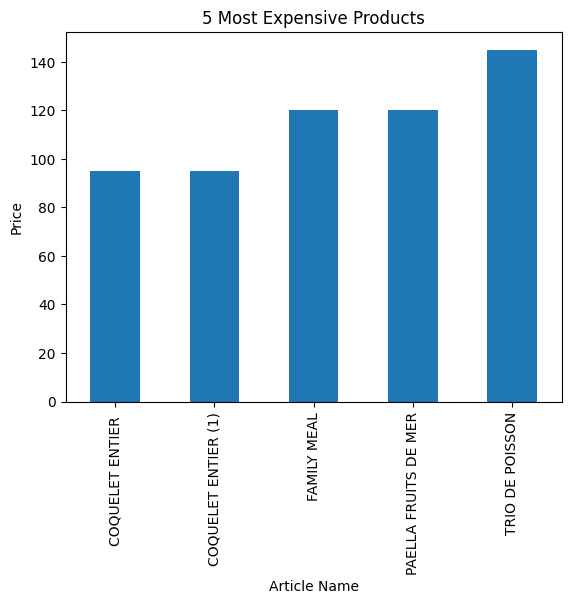

In [194]:
import matplotlib.pyplot as plt

# Average price per product
prices = df_article.groupby('Article Name')['Price'].mean()

# 5 most expensive products
prices.nlargest(5).sort_values().plot(kind='bar', title='5 Most Expensive Products')
plt.ylabel('Price')
plt.show()

In [195]:
df_journee.head()

,Date,Annuled Amount,Total Amount,Sales Number,Cashier
0,2000-08-02,396.0,886.0,9.0,1
1,2000-08-03,1099.0,1981.0,24.0,3
2,2000-08-04,0.0,275.0,3.0,1
3,2000-08-05,0.0,0.0,NaN,4
4,2000-08-06,1511.0,2090.0,27.0,4


In [196]:
df_journee.isnull().sum()

Date               0
Annuled Amount    27
Total Amount      27
Sales Number      31
Cashier            0
dtype: int64

In [197]:
df_journee = df_journee.dropna(subset=["Sales Number"])

In [198]:
df_journee.isnull().sum()

Date              0
Annuled Amount    0
Total Amount      0
Sales Number      0
Cashier           0
dtype: int64

As we can see, some records contain incorrect dates from the year 2000.

In [199]:
df_journee.drop(
    df_journee[df_journee["Date"] < pd.Timestamp("2023-01-01").date()].index,
    inplace=True
)

In [200]:
df_journee.info()

<class 'pandas.DataFrame'>
Index: 850 entries, 8 to 886
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Date            850 non-null    object 
 1   Annuled Amount  850 non-null    float64
 2   Total Amount    850 non-null    float64
 3   Sales Number    850 non-null    float64
 4   Cashier         850 non-null    int64  
dtypes: float64(3), int64(1), object(1)
memory usage: 39.8+ KB


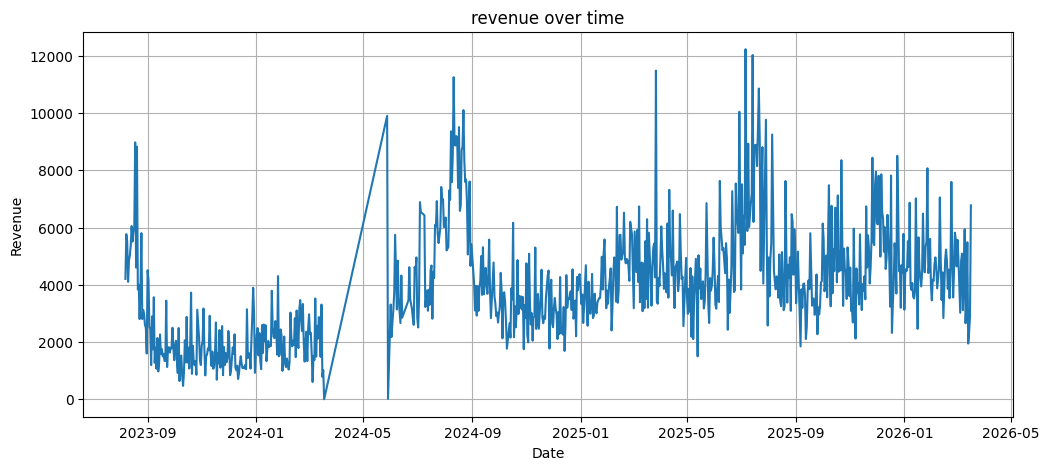

In [201]:
import matplotlib.pyplot as plt
daily_revenue = df_journee.groupby(df_journee["Date"])["Total Amount"].sum()

daily_revenue.plot(figsize=(12, 5), title="revenue over time")
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.grid()
plt.show()


now we ara trying to do stuff optimimization by saying the percentage of annulation from the total oreders that the cashier does 

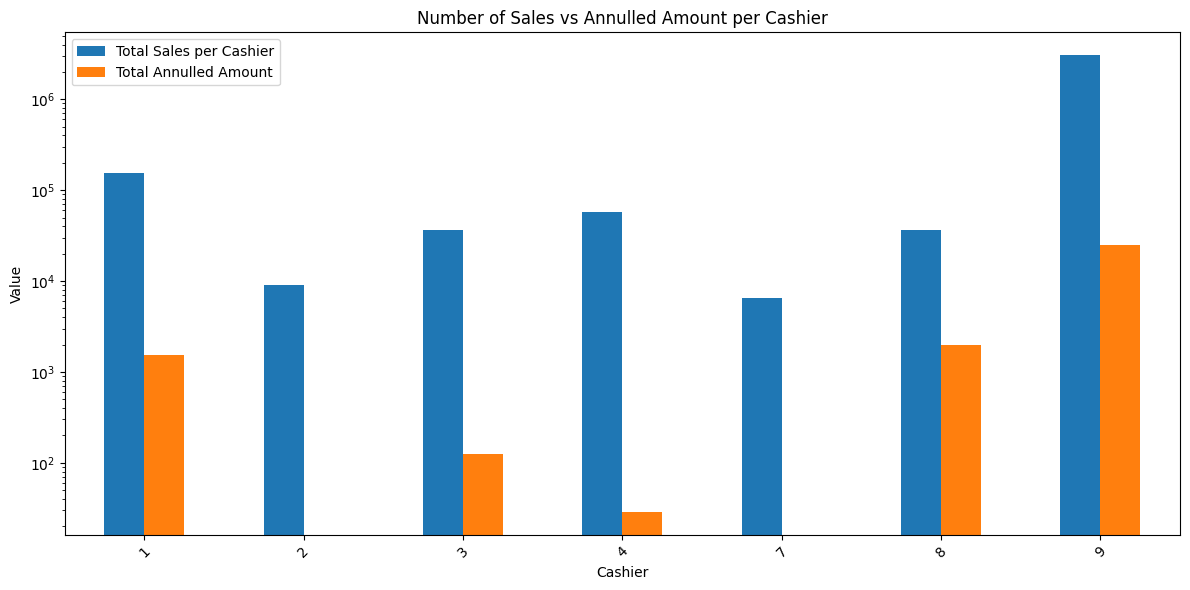

In [202]:
sales_per_cashier = df_journee.groupby("Cashier")["Total Amount"].sum()

annuled_per_cashier = df_journee.groupby("Cashier")["Annuled Amount"].sum()

comparison = pd.DataFrame({
    "Total Sales per Cashier": sales_per_cashier,
    "Total Annulled Amount": annuled_per_cashier
})
comparison.plot(kind="bar", figsize=(12, 6),logy=True)

plt.xlabel("Cashier")
plt.ylabel("Value")
plt.title("Number of Sales vs Annulled Amount per Cashier")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

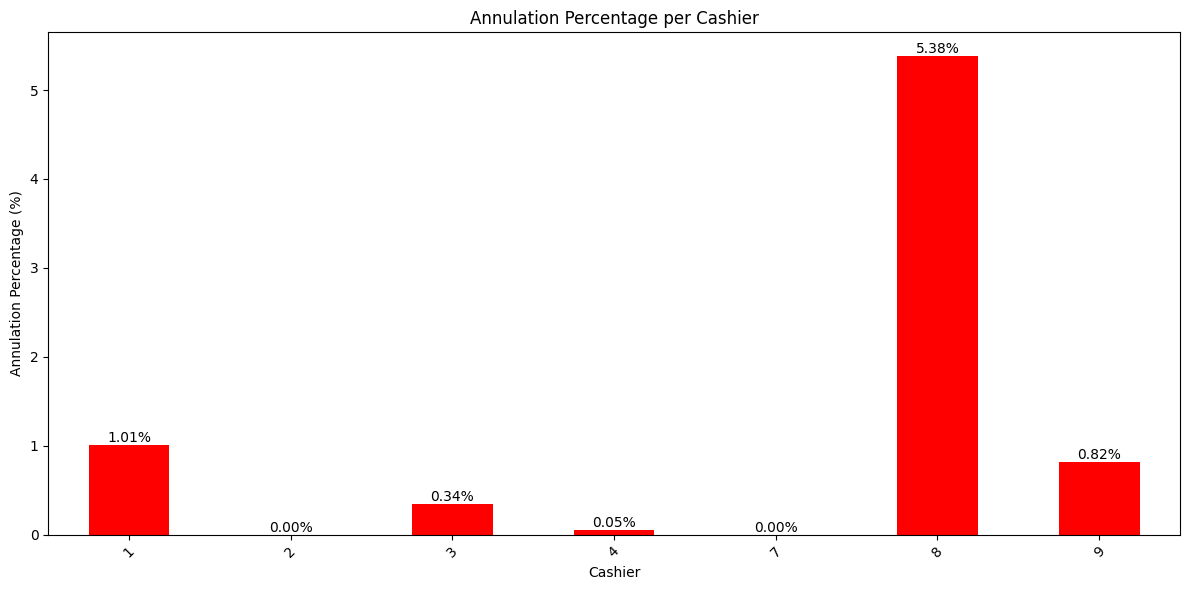

In [203]:
sales_per_cashier = df_journee.groupby("Cashier")["Total Amount"].sum()

annuled_per_cashier = df_journee.groupby("Cashier")["Annuled Amount"].sum()

comparison = pd.DataFrame({
    "Total Sales": sales_per_cashier,
    "Total Annulled Amount": annuled_per_cashier
})

# Calculate annulation percentage
comparison["Annulation Percentage"] = (
    comparison["Total Annulled Amount"] /
    comparison["Total Sales"]
) * 100

ax = comparison["Annulation Percentage"].plot(
    kind="bar",
    figsize=(12, 6),
    color="red"
)

plt.xlabel("Cashier")
plt.ylabel("Annulation Percentage (%)")
plt.title("Annulation Percentage per Cashier")
plt.xticks(rotation=45)

# Display percentage above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.show()

We can see that Cashier 8 had an annulment rate of more than 5% of their total orders, which is significantly higher than that of the other cashiers.

by merging article table with order table we can get more details 

In [204]:
df_sales = pd.merge(
    df_orders, dfcma,
    on='Order Id',
    how='inner'
)

In [205]:
df_sales.head()

,Order Id,Order Time,Payement Type,Order Amount,Order Type,Cashier,Day Id,Article Saled Time,Article Name,Total Amount,Quantity
0,1,2023-08-03 15:22:51,ESPECES,295.0,P,3,1,2023-08-03 15:14:07,PIZZA 4 FROMAGES,60.0,1.0
1,1,2023-08-03 15:22:51,ESPECES,295.0,P,3,1,2023-08-03 15:14:07,PIZZA 4 SAISONS,75.0,1.0
2,1,2023-08-03 15:22:51,ESPECES,295.0,P,3,1,2023-08-03 15:14:07,PIZZA AU SAUMON,160.0,2.0
3,2,2023-08-03 15:16:34,ESPECES,29.0,P,3,1,2023-08-03 15:14:19,OULMES 50CL,10.0,1.0
4,2,2023-08-03 15:16:34,ESPECES,29.0,P,3,1,2023-08-03 15:14:19,SIDI ALI 1.5L,12.0,1.0


In [206]:
df_sales = df_sales.drop(columns=["Order Id","Order Time","Order Amount"])

In [207]:
df_sales.head()

,Payement Type,Order Type,Cashier,Day Id,Article Saled Time,Article Name,Total Amount,Quantity
0,ESPECES,P,3,1,2023-08-03 15:14:07,PIZZA 4 FROMAGES,60.0,1.0
1,ESPECES,P,3,1,2023-08-03 15:14:07,PIZZA 4 SAISONS,75.0,1.0
2,ESPECES,P,3,1,2023-08-03 15:14:07,PIZZA AU SAUMON,160.0,2.0
3,ESPECES,P,3,1,2023-08-03 15:14:19,OULMES 50CL,10.0,1.0
4,ESPECES,P,3,1,2023-08-03 15:14:19,SIDI ALI 1.5L,12.0,1.0


In [208]:
df_sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 96046 entries, 0 to 96045
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Payement Type       94986 non-null  str    
 1   Order Type          94541 non-null  str    
 2   Cashier             96046 non-null  int64  
 3   Day Id              96046 non-null  int64  
 4   Article Saled Time  95863 non-null  str    
 5   Article Name        96046 non-null  str    
 6   Total Amount        96046 non-null  float64
 7   Quantity            96046 non-null  float64
dtypes: float64(2), int64(2), str(4)
memory usage: 9.6 MB


In [209]:
df_sales.isnull().sum()

Payement Type         1060
Order Type            1505
Cashier                  0
Day Id                   0
Article Saled Time     183
Article Name             0
Total Amount             0
Quantity                 0
dtype: int64

Missing values in the Payment Type and Order Type columns were replaced with the most frequent value (mode). Rows with missing values in the Article Sale Time column were removed.

In [210]:
most_common_payement_type = df_sales["Payement Type"].mode()[0]
most_common_order_type = df_sales["Payement Type"].mode()[0]


df_sales["Payement Type"] = df_sales["Payement Type"].fillna(most_common_payement_type)
df_sales["Order Type"] = df_sales["Payement Type"].fillna(most_common_order_type)

In [211]:
df_sales = df_sales.dropna(subset=["Article Saled Time"])

In [212]:
print("Exact duplicate rows:", df_sales.duplicated().sum())

Exact duplicate rows: 509


Duplicate articles in the dataset are expected because some articles are sold together as part of a menu or combination order. Therefore, these repeated rows do not necessarily indicate duplicate records or data entry errors.

In [213]:
df_sales.isnull().sum()

Payement Type         0
Order Type            0
Cashier               0
Day Id                0
Article Saled Time    0
Article Name          0
Total Amount          0
Quantity              0
dtype: int64

In [214]:
df_sales["Article Saled Time"] = pd.to_datetime(
    df_sales["Article Saled Time"],
    errors="coerce"
)

In [215]:
display(df_sales[df_sales.duplicated(keep=False)].head())

,Payement Type,Order Type,Cashier,Day Id,Article Saled Time,Article Name,Total Amount,Quantity
351,ESPECES,ESPECES,1,18,2023-08-05 11:29:40,OMLETTE CREVETTES,30.0,1.0
353,ESPECES,ESPECES,1,18,2023-08-05 11:29:40,OMLETTE CREVETTES,30.0,1.0
354,ESPECES,ESPECES,1,18,2023-08-05 11:31:03,OMLETTE CHARCUTERIE,25.0,1.0
355,ESPECES,ESPECES,1,18,2023-08-05 11:31:03,OMLETTE CREVETTES,30.0,1.0
356,ESPECES,ESPECES,1,18,2023-08-05 11:31:03,OMLETTE FROMAGE,25.0,1.0


In [216]:
df_sales_dates = df_sales.copy()

In [217]:
df_sales_dates.info()

<class 'pandas.DataFrame'>
Index: 95863 entries, 0 to 96045
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Payement Type       95863 non-null  str           
 1   Order Type          95863 non-null  str           
 2   Cashier             95863 non-null  int64         
 3   Day Id              95863 non-null  int64         
 4   Article Saled Time  95863 non-null  datetime64[us]
 5   Article Name        95863 non-null  str           
 6   Total Amount        95863 non-null  float64       
 7   Quantity            95863 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(3)
memory usage: 9.1 MB


In [218]:
df_sales_dates["Date"] = df_sales_dates["Article Saled Time"].dt.date
df_sales_dates["Year"] = df_sales_dates["Article Saled Time"].dt.year
df_sales_dates["Month"] = df_sales_dates["Article Saled Time"].dt.month
df_sales_dates["Day"] = df_sales_dates["Article Saled Time"].dt.day
df_sales_dates["Day Name"] = df_sales_dates["Article Saled Time"].dt.day_name()
df_sales_dates["Hour"] = df_sales_dates["Article Saled Time"].dt.hour

In [219]:
df_sales_dates.head(20)

,Payement Type,Order Type,Cashier,Day Id,Article Saled Time,Article Name,Total Amount,Quantity,Date,Year,Month,Day,Day Name,Hour
0,ESPECES,ESPECES,3,1,2023-08-03 15:14:07,PIZZA 4 FROMAGES,60.0,1.0,2023-08-03,2023,8,3,Thursday,15
1,ESPECES,ESPECES,3,1,2023-08-03 15:14:07,PIZZA 4 SAISONS,75.0,1.0,2023-08-03,2023,8,3,Thursday,15
2,ESPECES,ESPECES,3,1,2023-08-03 15:14:07,PIZZA AU SAUMON,160.0,2.0,2023-08-03,2023,8,3,Thursday,15
3,ESPECES,ESPECES,3,1,2023-08-03 15:14:19,OULMES 50CL,10.0,1.0,2023-08-03,2023,8,3,Thursday,15
4,ESPECES,ESPECES,3,1,2023-08-03 15:14:19,SIDI ALI 1.5L,12.0,1.0,2023-08-03,2023,8,3,Thursday,15
5,ESPECES,ESPECES,3,1,2023-08-03 15:14:19,SIDI ALI 50CL,7.0,1.0,2023-08-03,2023,8,3,Thursday,15
6,ESPECES,ESPECES,3,1,2023-08-03 15:14:53,ASSORTIMENT DE GLACES,40.0,1.0,2023-08-03,2023,8,3,Thursday,15
7,ESPECES,ESPECES,3,1,2023-08-03 15:15:10,SALADE CÉSAR,65.0,1.0,2023-08-03,2023,8,3,Thursday,15
8,ESPECES,ESPECES,3,1,2023-08-03 15:15:10,TARTARE AVOCAT CREVETTES,60.0,1.0,2023-08-03,2023,8,3,Thursday,15
9,ESPECES,ESPECES,3,1,2023-08-03 15:15:10,SALADE VIET,70.0,1.0,2023-08-03,2023,8,3,Thursday,15


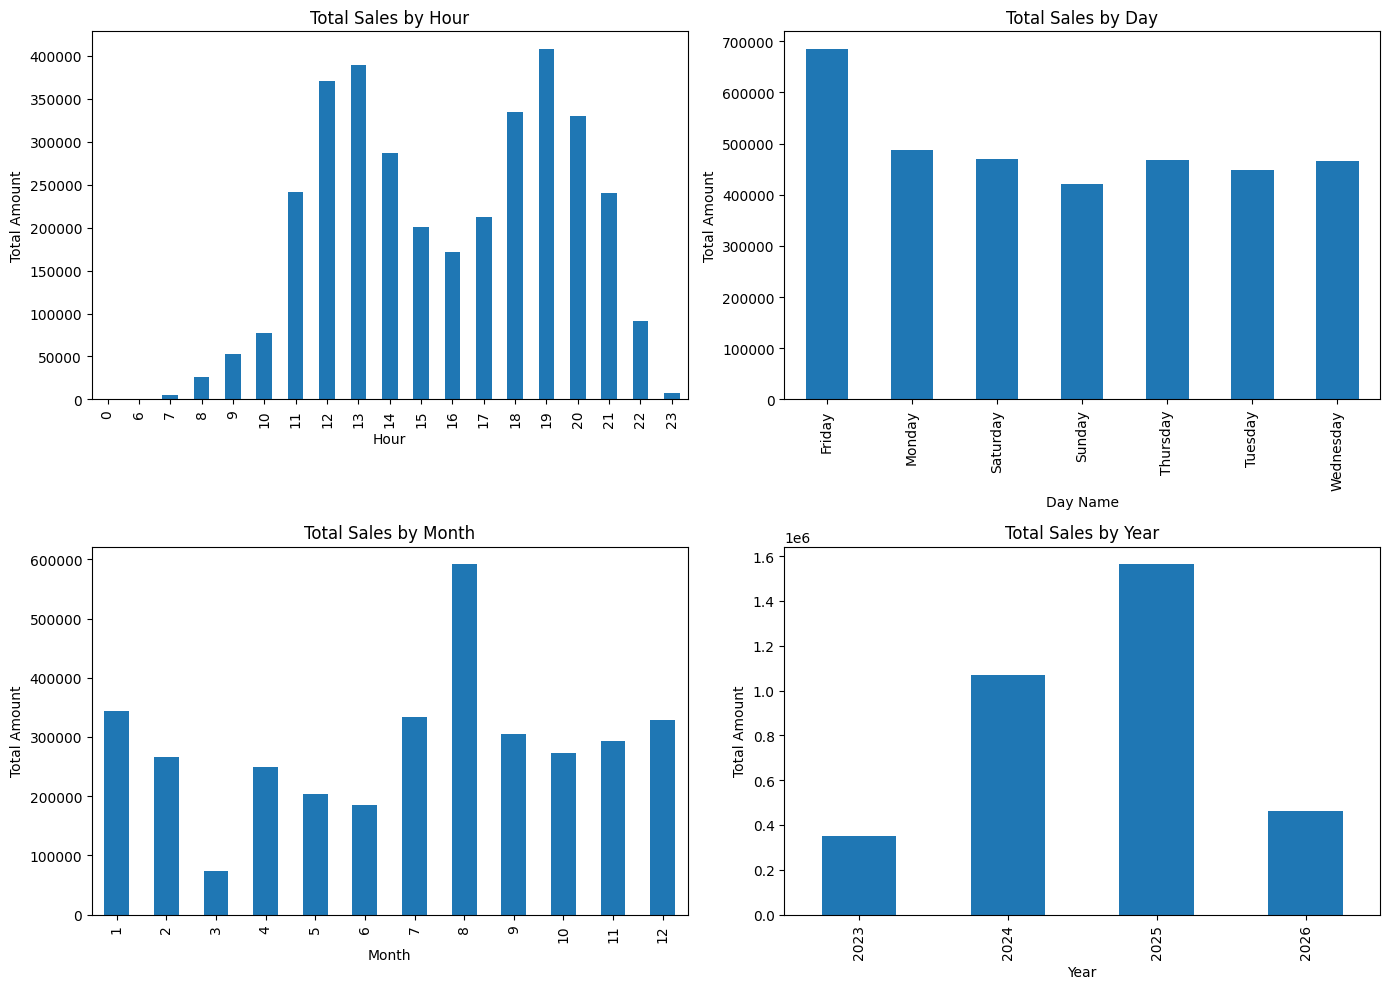

In [220]:
import matplotlib.pyplot as plt

# Calculate sales
hourly_sales = df_sales_dates.groupby("Hour")["Total Amount"].sum()
daily_sales = df_sales_dates.groupby("Day Name")["Total Amount"].sum()
monthly_sales = df_sales_dates.groupby("Month")["Total Amount"].sum()
yearly_sales = df_sales_dates.groupby("Year")["Total Amount"].sum()

# Create a 2x2 figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Sales by hour
hourly_sales.sort_index().plot(
    kind="bar", ax=axes[0, 0], title="Total Sales by Hour"
)
axes[0, 0].set_ylabel("Total Amount")

# 2. Sales by day of week
daily_sales.plot(
    kind="bar", ax=axes[0, 1], title="Total Sales by Day"
)
axes[0, 1].set_ylabel("Total Amount")

# 3. Sales by month
monthly_sales.sort_index().plot(
    kind="bar", ax=axes[1, 0], title="Total Sales by Month"
)
axes[1, 0].set_ylabel("Total Amount")

# 4. Sales by year
yearly_sales.sort_index().plot(
    kind="bar", ax=axes[1, 1], title="Total Sales by Year"
)
axes[1, 1].set_ylabel("Total Amount")

plt.tight_layout()
plt.show()

This plot provides further insights into the busiest and quietest periods of the restaurant throughout the day, week, month, and year.

- **Hours:** The busiest hours are 12:00–13:00 and 18:00–20:00, corresponding to lunchtime and evening demand.
- **Days:** Friday is the busiest day of the week.
- **Months:** July, August, and September show the highest levels of activity.
- **Years:** 2025 was the busiest year compared with the previous years. However, this comparison should be interpreted carefully because the 2026 dataset is incomplete.

These patterns help identify peak-demand periods and can support better staff scheduling and inventory planning.

In [221]:
payementsTypes = df_sales_dates.groupby('Payement Type')['Total Amount'].size()


In [222]:
payementsTypes.head()

Payement Type
CARTE         95
ESPECES    95768
Name: Total Amount, dtype: int64

In [223]:
payementsTypes.head()
cadrte_percentage = payementsTypes["CARTE"]/(payementsTypes["CARTE"]+payementsTypes["ESPECES"])*100
print("Card Percentage is",cadrte_percentage)


Card Percentage is 0.09909975694480666


Card payments account for less than 0.1% of total transactions.

In [224]:
#%pip install plotly ipywidgets

In [225]:
df_sales_dates.info()

<class 'pandas.DataFrame'>
Index: 95863 entries, 0 to 96045
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Payement Type       95863 non-null  str           
 1   Order Type          95863 non-null  str           
 2   Cashier             95863 non-null  int64         
 3   Day Id              95863 non-null  int64         
 4   Article Saled Time  95863 non-null  datetime64[us]
 5   Article Name        95863 non-null  str           
 6   Total Amount        95863 non-null  float64       
 7   Quantity            95863 non-null  float64       
 8   Date                95863 non-null  object        
 9   Year                95863 non-null  int32         
 10  Month               95863 non-null  int32         
 11  Day                 95863 non-null  int32         
 12  Day Name            95863 non-null  str           
 13  Hour                95863 non-null  int32         
dtypes: dat

In [226]:

import pandas as pd
import json
import os

# Prepare data for the interactive chart
chart_data = (
    df_sales_dates.groupby(
        ["Hour", "Day Name", "Article Name"]
    )["Total Amount"]
    .sum()
    .reset_index()
)

# Convert data to JSON
data_json = json.dumps(
    chart_data.to_dict(orient="records"),
    ensure_ascii=False
).replace("</", "<\\/")

# Create GitHub Pages folder
os.makedirs("docs", exist_ok=True)

html = """
<!DOCTYPE html>
<html>
<head>
    <title>Restaurant Sales Analysis</title>
    <script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
    <style>
        body {
            font-family: Arial, sans-serif;
            margin: 30px;
        }
        .filters {
            display: flex;
            gap: 20px;
            margin-bottom: 20px;
        }
        select {
            padding: 8px;
            min-width: 150px;
        }
    </style>
</head>

<body>

<h2>Top 10 Articles by Revenue</h2>

<div class="filters">
    <label>Hour:
        <select id="hour"></select>
    </label>

    <label>Weekday:
        <select id="day"></select>
    </label>
</div>

<div id="chart" style="width:100%; height:650px;"></div>

<script>

const data = DATA_PLACEHOLDER;

const days = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
];

const hourSelect = document.getElementById("hour");
const daySelect = document.getElementById("day");

function addOption(select, value, label) {
    let option = document.createElement("option");
    option.value = value;
    option.textContent = label;
    select.appendChild(option);
}

addOption(hourSelect, "All", "All hours");

for (let h = 0; h < 24; h++) {
    addOption(hourSelect, h, h + ":00");
}

addOption(daySelect, "All", "All days");

days.forEach(day => addOption(daySelect, day, day));

function updateChart() {

    let hour = hourSelect.value;
    let day = daySelect.value;

    let filtered = data.filter(row =>
        (hour === "All" || Number(row.Hour) === Number(hour)) &&
        (day === "All" || row["Day Name"] === day)
    );

    let totals = {};

    filtered.forEach(row => {
        totals[row["Article Name"]] =
            (totals[row["Article Name"]] || 0) +
            Number(row["Total Amount"]);
    });

    let top10 = Object.entries(totals)
        .sort((a, b) => b[1] - a[1])
        .slice(0, 10)
        .sort((a, b) => a[1] - b[1]);

    let trace = {
        x: top10.map(item => item[1]),
        y: top10.map(item => item[0]),
        type: "bar",
        orientation: "h"
    };

    let title = "Top 10 Articles by Revenue";

    Plotly.react("chart", [trace], {
        title: title,
        xaxis: {title: "Total Revenue"},
        yaxis: {title: "Article Name"},
        margin: {l: 160, r: 30, t: 60, b: 60},
        autosize: true
    }, {responsive: true});
}

hourSelect.addEventListener("change", updateChart);
daySelect.addEventListener("change", updateChart);

updateChart();

</script>

</body>
</html>
"""

html = html.replace("DATA_PLACEHOLDER", data_json)

with open("docs/index.html", "w", encoding="utf-8") as f:
    f.write(html)

print("Interactive HTML created successfully!")


Interactive HTML created successfully!


In [227]:
import pandas as pd
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display



# Create filters
hour_filter = widgets.Dropdown(
    options=["All"] + list(range(24)),
    value="All",
    description="Hour:"
)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

day_filter = widgets.Dropdown(
    options=["All"] + day_order,
    value="All",
    description="Weekday:"
)

def update_chart(hour, day):
    data = df_sales_dates.copy()

    if hour != "All":
        data = data[data["Hour"] == hour]

    if day != "All":
        data = data[data["Day Name"] == day]

    # Total revenue per product
    prices = (
        data.groupby("Article Name")["Total Amount"]
        .sum()
        .nlargest(10)
        .sort_values()
        .reset_index()
    )

    fig = px.bar(
        prices,
        x="Total Amount",
        y="Article Name",
        orientation="h",
        title="Top 10 Products by Revenue",
        labels={"Total Amount": "Revenue"},
        height=600,
        width=1000
    )

    fig.show()

out = widgets.interactive_output(
    update_chart,
    {"hour": hour_filter, "day": day_filter}
)

display(widgets.HBox([hour_filter, day_filter]), out)

Output()

This interactive plot helps identify the best-selling articles based on the hour of the day and the day of the week, providing insights into customer purchasing patterns.

In [228]:
df_sales_dates['Quantity'] = pd.to_numeric(df_sales_dates['Quantity'], errors='coerce')

In [229]:
df_quan = df_sales_dates.copy()

# start weeks on monday
df_quan["Week"] = df_quan["Article Saled Time"].dt.to_period("W").dt.start_time

weekly_sales = (
    df_quan.groupby(["Week", "Article Name"])["Quantity"]
    .sum()
    .unstack(fill_value=0)
    .sort_index()
)
print(df_quan["Quantity"].dtype)

float64


In [230]:
last_4 = weekly_sales.tail(4).mean()
previous_4 = weekly_sales.iloc[-8:-4].mean()

comparison = pd.DataFrame({
    "Previous 4 Weeks": previous_4,
    "Last 4 Weeks": last_4
})

comparison["Change %"]= (
    (comparison["Last 4 Weeks"] - comparison["Previous 4 Weeks"]) 
    / comparison["Previous 4 Weeks"].replace(0, float("nan"))
*100
)

declining = comparison[
    comparison["Change %"] < -20
].sort_values("Change %")

This plot highlights articles with declining sales by comparing the previous month with the most recent month, ranked from the largest to the smallest decrease.

In [231]:
declining.head()

,Previous 4 Weeks,Last 4 Weeks,Change %
Article Name,,,
DINNER BOX,0.50,0.00,-100.0
HUILE D'OLIVE,0.25,0.00,-100.0
MIEL,0.25,0.00,-100.0
OMLETTE TOMATE 2,1.25,0.25,-80.0
OMLETTE TOMATE 4,1.00,0.25,-75.0


In [232]:

import json
import os

# Prepare weekly sales data
sales_data = weekly_sales.reset_index()

# Identify the week column
week_col = sales_data.columns[0]

# Convert to JSON
data_json = json.dumps(
    sales_data.to_dict(orient="records"),
    default=str
).replace("</", "<\\/")

# Create docs folder
os.makedirs("docs", exist_ok=True)

html = """
<!DOCTYPE html>
<html>
<head>
    <title>Weekly Article Sales Trends</title>
    <script src="https://cdn.plot.ly/plotly-2.35.2.min.js"></script>
    <style>
        body {
            font-family: Arial;
            margin: 30px;
        }
        select {
            padding: 10px;
            min-width: 250px;
            margin-bottom: 20px;
        }
    </style>
</head>

<body>

<h2>Weekly Sales Trend by Article</h2>

<label>Select Article:</label>
<br>
<select id="product"></select>

<div id="chart" style="width:100%;height:550px;"></div>

<script>

const data = DATA_PLACEHOLDER;

const productSelect = document.getElementById("product");

// All article names except the first week/index column
const products = Object.keys(data[0]).filter(
    key => key !== "WEEK_PLACEHOLDER"
);

products.forEach(product => {
    let option = document.createElement("option");
    option.value = product;
    option.textContent = product;
    productSelect.appendChild(option);
});

function updateChart() {

    const product = productSelect.value;

    const weeks = data.map(row => row["WEEK_PLACEHOLDER"]);
    const quantities = data.map(row => row[product]);

    Plotly.react("chart", [{
        x: weeks,
        y: quantities,
        type: "scatter",
        mode: "lines+markers",
        name: product
    }], {
        title: "Weekly Sales Trend: " + product,
        xaxis: {title: "Week"},
        yaxis: {title: "Quantity Sold"},
        margin: {l: 70, r: 30, t: 60, b: 100}
    }, {responsive: true});
}

productSelect.addEventListener("change", updateChart);

updateChart();

</script>

</body>
</html>
"""

html = html.replace("DATA_PLACEHOLDER", data_json)
html = html.replace("WEEK_PLACEHOLDER", week_col)

with open("docs/weekly_sales.html", "w", encoding="utf-8") as f:
    f.write(html)

print("Interactive weekly sales page created!")


Interactive weekly sales page created!


In [233]:
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display

def plot_sales(product):
    weekly_sales[product].plot(
        figsize=(12, 5),
        marker="o",
        title=f"Weekly Sales Trend: {product}"
    )

    plt.xlabel("Week")
    plt.ylabel("Quantity Sold")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

product_dropdown = widgets.Dropdown(
    options=weekly_sales.columns.tolist(),
    description="Product:",
    value=declining.index[0]
)

widgets.interactive(plot_sales, product=product_dropdown)

interactive(children=(Dropdown(description='Product:', index=65, options=('#CHOIX BOISSON CHAUD', 'AMAZIGH', '…

This plot shows how article sales have changed over the entire period, highlighting trends, fluctuations, and changes in demand over time.

In [234]:
product_name = "CONFITURE"
product_sales = weekly_sales[product_name]

std = product_sales.std()

if std > 0:
    z_score = (
        (product_sales - product_sales.mean()) / std
    )

    unusual = product_sales[
        z_score.abs() > 2
    ]

    display(unusual.sort_values())
else:
    print("Sales do not vary for this product.")

Week
2023-09-11     3.0
2023-10-02     3.0
2023-09-25     4.0
2023-09-18    10.0
Name: CONFITURE, dtype: float64

In [235]:
df_sales.head()

,Payement Type,Order Type,Cashier,Day Id,Article Saled Time,Article Name,Total Amount,Quantity
0,ESPECES,ESPECES,3,1,2023-08-03 15:14:07,PIZZA 4 FROMAGES,60.0,1.0
1,ESPECES,ESPECES,3,1,2023-08-03 15:14:07,PIZZA 4 SAISONS,75.0,1.0
2,ESPECES,ESPECES,3,1,2023-08-03 15:14:07,PIZZA AU SAUMON,160.0,2.0
3,ESPECES,ESPECES,3,1,2023-08-03 15:14:19,OULMES 50CL,10.0,1.0
4,ESPECES,ESPECES,3,1,2023-08-03 15:14:19,SIDI ALI 1.5L,12.0,1.0


In [236]:
df_copy = df_sales.copy()
print("First sale:", df_copy["Article Saled Time"].min())
print("Last sale:", df_copy["Article Saled Time"].max())

print(
    "Number of months:",
    df_copy["Article Saled Time"].dt.to_period("M").nunique()
)

print(
    "Number of unique articles:",
    df_copy["Article Name"].nunique()
)

First sale: 2023-08-03 15:14:07
Last sale: 2026-05-15 20:24:54
Number of months: 32
Number of unique articles: 331


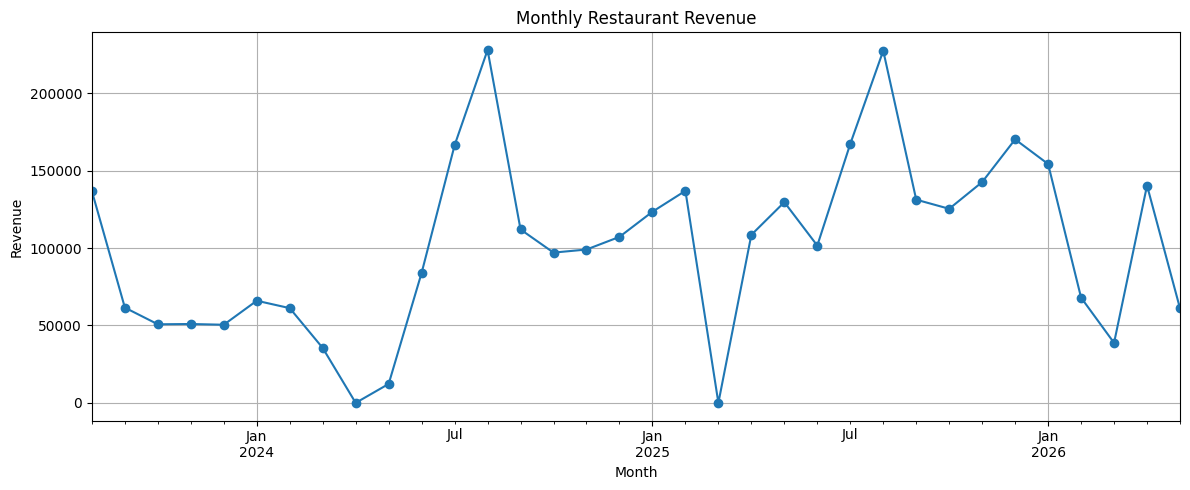

In [237]:
import pandas as pd
import matplotlib.pyplot as plt

# Create a clean copy for revenue forecasting
df_revenue = df_copy.dropna(
    subset=["Article Saled Time", "Total Amount"]
).copy()

df_revenue["Total Amount"] = pd.to_numeric(
    df_revenue["Total Amount"], errors="coerce"
)

df_revenue = df_revenue.dropna(subset=["Total Amount"])

# Calculate total revenue per month
monthly_revenue = (
    df_revenue
    .set_index("Article Saled Time")["Total Amount"]
    .resample("MS")
    .sum()
)

# # Display monthly revenue
# display(monthly_revenue.to_frame("Revenue"))

# Plot the data
monthly_revenue.plot(
    figsize=(12, 5),
    marker="o",
    title="Monthly Restaurant Revenue"
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()

we find out that monthly revenue is not helping us as much to do analyse and prediction 

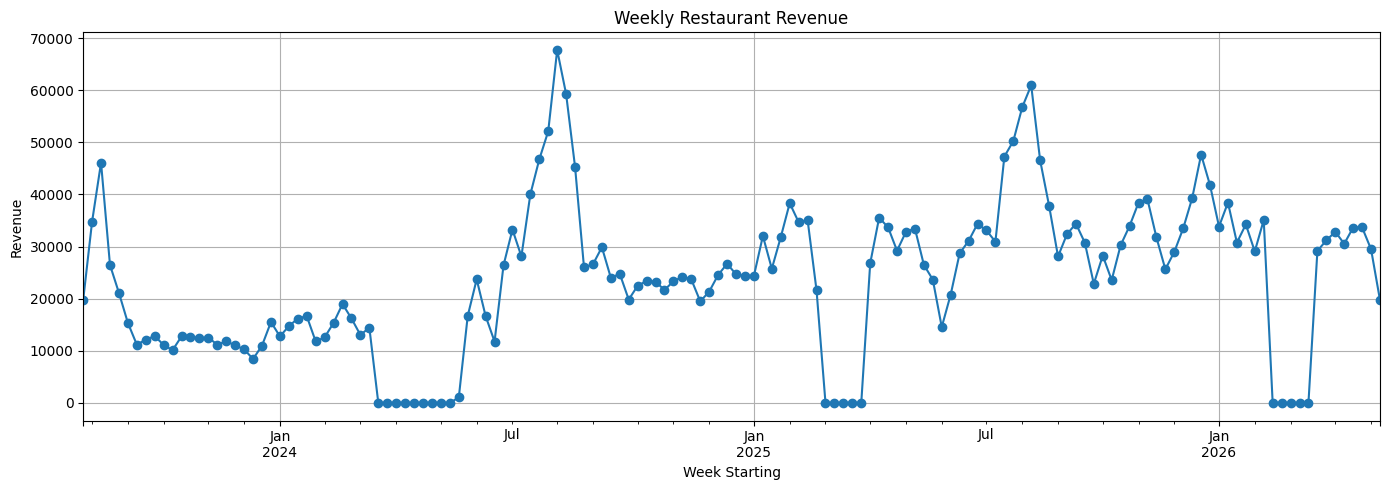

In [238]:
import pandas as pd
import matplotlib.pyplot as plt

# Keep valid dates and revenue amounts
df_weekly = df_copy.dropna(
    subset=["Article Saled Time", "Total Amount"]
).copy()

df_weekly["Total Amount"] = pd.to_numeric(
    df_weekly["Total Amount"], errors="coerce"
)

df_weekly = df_weekly.dropna(subset=["Total Amount"])

# Aggregate revenue by week, Monday to Sunday
weekly_revenue = (
    df_weekly
    .set_index("Article Saled Time")["Total Amount"]
    .resample("W-MON", closed="left", label="left")
    .sum()
)

# # Inspect weekly revenue
# display(weekly_revenue.tail(10).to_frame("Weekly Revenue"))

# Plot
weekly_revenue.plot(
    figsize=(14, 5),
    title="Weekly Restaurant Revenue",
    marker="o"
)

plt.xlabel("Week Starting")
plt.ylabel("Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()

Total calendar days: 1017
Days with zero revenue: 0
Days with missing revenue: 153


Article Saled Time
2024-05-25    240.0
2023-10-11    486.0
2025-06-10    588.0
2024-03-05    602.0
2023-10-07    680.0
Name: Total Amount, dtype: float64

,Start_Date,End_Date,Days_Without_Records
0,2024-03-18,2024-05-24,68
3,2025-03-01,2025-04-06,37
5,2026-02-16,2026-03-24,37
2,2024-06-15,2024-06-20,6
4,2025-06-06,2025-06-09,4
1,2024-05-27,2024-05-27,1


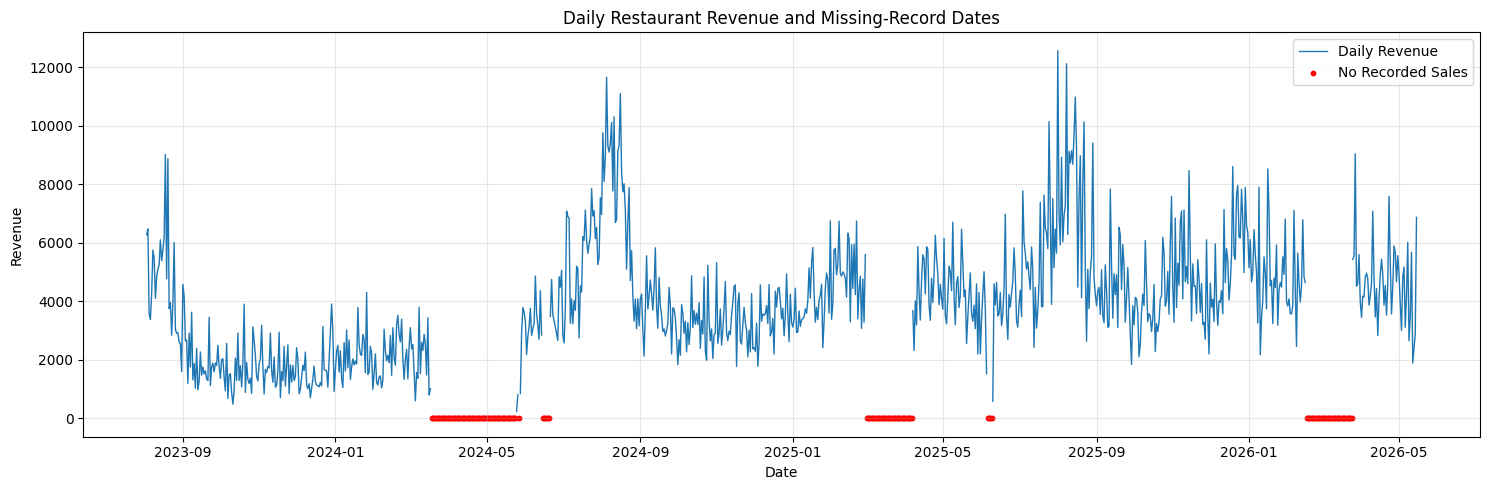

In [239]:
daily_revenue = (
    df_sales_dates.dropna(subset=["Article Saled Time"])
      .set_index("Article Saled Time")["Total Amount"]
      .resample("D")
      .sum(min_count=1)
)

print("Total calendar days:", len(daily_revenue))
print("Days with zero revenue:", daily_revenue.eq(0).sum())
print("Days with missing revenue:", daily_revenue.isna().sum())

display(daily_revenue.sort_values().head())

# Identify dates with no recorded revenue
missing_days = daily_revenue[daily_revenue.isna()].index

# Convert missing dates to a DataFrame
missing_df = pd.DataFrame({"Date": missing_days})

# Group consecutive calendar dates together
missing_df["Group"] = (
    missing_df["Date"].diff().dt.days.ne(1)
).cumsum()

# Summarise each period
possible_closures = (
    missing_df.groupby("Group")
    .agg(
        Start_Date=("Date", "min"),
        End_Date=("Date", "max"),
        Days_Without_Records=("Date", "size")
    )
    .reset_index(drop=True)
)

# Show the longest periods first
possible_closures = possible_closures.sort_values(
    "Days_Without_Records", ascending=False
)

display(possible_closures)



import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    daily_revenue.index,
    daily_revenue.values,
    label="Daily Revenue",
    linewidth=1
)

# Highlight missing-record dates
missing_dates = daily_revenue[daily_revenue.isna()].index

plt.scatter(
    missing_dates,
    [0] * len( missing_dates),
    color="red",
    s=10,
    label="No Recorded Sales"
)

plt.title("Daily Restaurant Revenue and Missing-Record Dates")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

we find out that we have some missing values , and were trying to discver if its reapting every year 

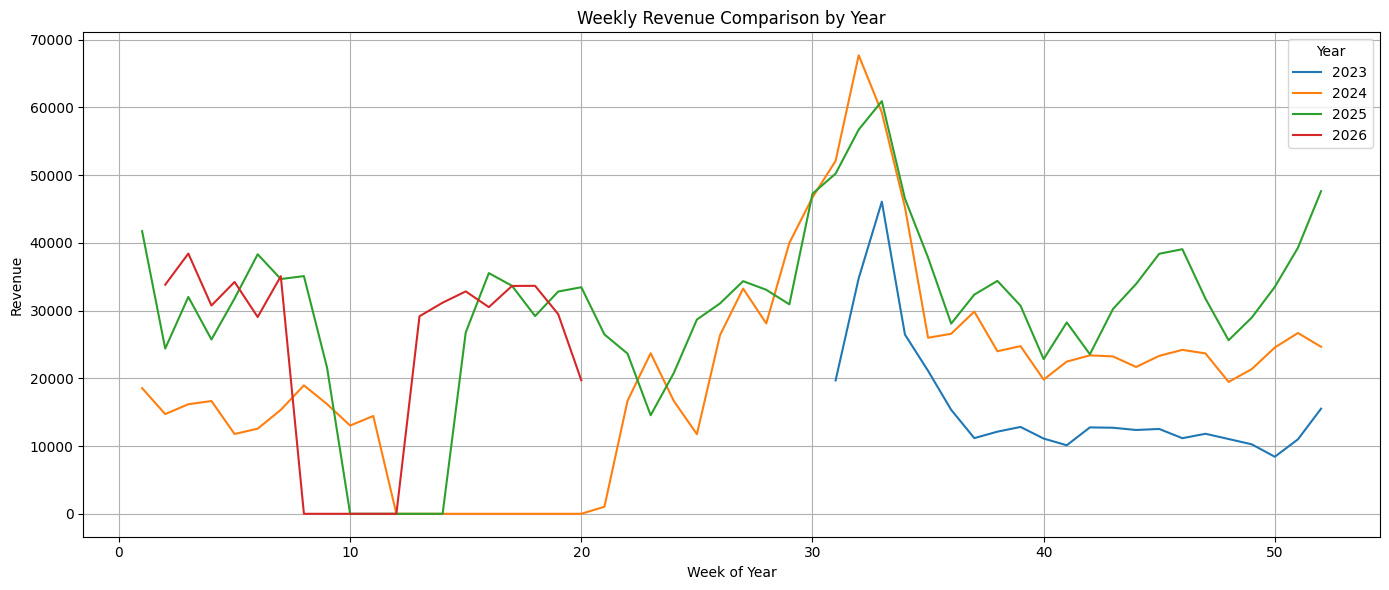

In [240]:
weekly_analysis = weekly_revenue.to_frame("Revenue").copy()

weekly_analysis["Year"] = weekly_analysis.index.year
weekly_analysis["Week Number"] = (
    weekly_analysis.index.isocalendar().week.astype(int)
)

# Compare weekly revenue across years
yearly_comparison = weekly_analysis.pivot_table(
    index="Week Number",
    columns="Year",
    values="Revenue",
    aggfunc="mean"
)

yearly_comparison.plot(
    figsize=(14, 6),
    title="Weekly Revenue Comparison by Year"
)

plt.xlabel("Week of Year")
plt.ylabel("Revenue")
plt.grid(True)
plt.tight_layout()
plt.show()

we can see that we have seasonal gap every year from fabrury to may when probabely the restaurant is refresing

In [241]:
import pandas as pd
import numpy as np

# Make sure the index is a datetime index
weekly = weekly_revenue.copy()
weekly.index = pd.to_datetime(weekly.index)
weekly = weekly.sort_index().asfreq("W-MON")

# Remove the final week if it is incomplete
last_date = df_copy["Article Saled Time"].max()
last_complete_week = (
    last_date.normalize()
    - pd.Timedelta(days=last_date.weekday() + 1)
)

weekly = weekly.loc[:last_complete_week]

print("First week:", weekly.index.min())
print("Last complete week:", weekly.index.max())
print("Number of weeks:", len(weekly))

First week: 2023-07-31 00:00:00
Last complete week: 2026-05-04 00:00:00
Number of weeks: 145


In [242]:
weekly = weekly.loc[weekly.index.notna()]

In [243]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error
# Define the testing period
# test_start = "2026-08-01"
# test_end = "2026-12-01"

# # Training: all weeks before 1 August 2026
# train = weekly.loc[weekly.index < test_start]

# # Testing: weeks from 1 August to 1 December 2026
# test = weekly.loc[
#     (weekly.index >= test_start) &
#     (weekly.index <= test_end)
# ]


train = weekly.iloc[:-8]
test = weekly.iloc[-8:]

# Model 1: Naive
pred_naive = pd.Series(
    [train.iloc[-1]] * len(test),
    index=test.index
)

# Model 2: Moving average of the previous 4 weeks
pred_ma = pd.Series(index=test.index, dtype=float)

history = train.copy()

for date in test.index:
    pred_ma.loc[date] = history.tail(4).mean()
    history.loc[date] = weekly.loc[date]

# Model 3: Exponential Smoothing without trend
model_es = ExponentialSmoothing(
    train,
    trend=None,
    seasonal=None,
    initialization_method="estimated"
).fit()

pred_es = model_es.forecast(len(test))
pred_es.index = test.index

# Model 4: Seasonal naive (52 weeks earlier)
pred_seasonal = weekly.shift(52).reindex(test.index)

# Combine predictions
comparison = pd.DataFrame({
    "Actual": test,
    "Naive": pred_naive,
    "Moving Average": pred_ma,
    "Exponential Smoothing": pred_es,
    "Seasonal Naive": pred_seasonal
})

comparison.head(20)

mae = pd.Series({
    "Naive": mean_absolute_error(test, pred_naive),
    "Moving Average": mean_absolute_error(test, pred_ma),
    "Exponential Smoothing": mean_absolute_error(test, pred_es),
    "Seasonal Naive": mean_absolute_error(test, pred_seasonal),
}).sort_values()

print("MAE by model:")
display(mae.round(2))

MAE by model:


Seasonal Naive            9906.50
Moving Average           10693.19
Naive                    27559.25
Exponential Smoothing    27559.25
dtype: float64

thos are the results of the models 
Seasonal Naive            9906.50
Moving Average           10693.19
Naive                    27559.25
Exponential Smoothing    27559.25
dtype: float64

seasonal naive looks great till now

# ARIMA

In [244]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Make sure the data is numeric and has a weekly frequency
train = train.astype(float).asfreq("W-MON")
test = test.astype(float)

# Fit SARIMA
model_sarima = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fit = model_sarima.fit(disp=False)

# Forecast the testing period
pred_sarima = sarima_fit.forecast(steps=len(test))
pred_sarima.index = test.index

# Evaluate
mae_sarima = mean_absolute_error(test, pred_sarima)

print("SARIMA MAE:", round(mae_sarima, 2))

c:\Users\Laptop\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'


SARIMA MAE: 22630.11


In [245]:
# plotds is method to plot time series, ACF and PACF
def plotds(xt, nlag = 30, fig_size = (12, 10)):            # Function to plot time series, ACF, and PACF
    if not isinstance(xt, pd.Series):                      # Check if input is not a pandas Series
         xt = pd.Series(xt)                                # Convert input to pandas Series if needed
         
    plt.figure(figsize = fig_size)                         # Create a figure with specified size
    layout = (2, 2)                                        # Define grid layout (2 rows x 2 columns)
    
    ax_xt = plt.subplot2grid(layout, (0, 0), colspan = 2)  # Top plot spans both columns (time series)
    ax_acf= plt.subplot2grid(layout, (1, 0))               # Bottom-left plot for ACF
    ax_pacf = plt.subplot2grid(layout, (1, 1))             # Bottom-right plot for PACF
    
    xt.plot(ax = ax_xt)                                    # Plot the time series data
    ax_xt.set_title('Time Series')                         # Set title for time series plot
    
    plot_acf(xt, lags = 50, ax = ax_acf)                   # Plot autocorrelation function (ACF)
    plot_pacf(xt, lags = 50, ax = ax_pacf)                 # Plot partial autocorrelation function (PACF)
    
    plt.tight_layout()                                     # Adjust layout to prevent overlapping
    return None                                            # Function returns nothing

In [246]:
from statsmodels.tsa.stattools import adfuller

# Call adfuller() function to calculate the values
adf_result = adfuller(weekly.dropna())
print('ADF Statistic: %f' % adf_result[0])
print('p-value: %f' % adf_result[1])

ADF Statistic: -3.842846
p-value: 0.002498


In [247]:
from statsmodels.tsa.arima.model import ARIMA

from statsmodels.tsa.statespace.sarimax import SARIMAX

print(SARIMAX)

<class 'statsmodels.tsa.statespace.sarimax.SARIMAX'>


In [248]:
# A nested loop is written to calculate the AIC values
aicVal = []                                      # Initialize an empty list to store ARIMA parameters and AIC values

for d in range(1, 3):                             # Loop over differencing order (d = 1 to 2)
    for ari in range(0, 3):                       # Loop over AR terms (p = 0 to 2)
        for maj in range(0, 3):                   # Loop over MA terms (q = 0 to 2)
            try:
                arima_obj = ARIMA(weekly, order=(ari, d, maj))  # Create ARIMA model with parameters (p=ari, d=d, q=maj)                
                arima_obj_fit = arima_obj.fit()                                    # Fit the ARIMA model to the data                
                aicVal.append([ari, d, maj, float(arima_obj_fit.aic)])             # Store p, d, q values along with the computed AIC
            except ValueError:                                                     # Handle cases where model fails to fit
                pass                                                               # Ignore errors and continue loop

# Print results line by line
for val in aicVal:                                                                 # Loop through stored AIC results
    print(val)                  

c:\Users\Laptop\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Laptop\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Laptop\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Laptop\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'
c:\Users\Laptop\anaconda3\

[0, 1, 0, 2987.411455876948]
[0, 1, 1, 2986.6024435528734]
[0, 1, 2, 2988.384562279568]
[1, 1, 0, 2986.4076870712533]
[1, 1, 1, 2988.59129682863]
[1, 1, 2, 2987.3556796267985]
[2, 1, 0, 2988.2523538683254]
[2, 1, 1, 2977.840379592655]
[2, 1, 2, 2978.862808517676]
[0, 2, 0, 3047.401782456136]
[0, 2, 1, 2976.3502743655627]
[0, 2, 2, 2975.000578656576]
[1, 2, 0, 3022.6629364659593]
[1, 2, 1, 2975.0071219335387]
[1, 2, 2, 2979.0786529124]
[2, 2, 0, 3016.511612681434]
[2, 2, 1, 2978.747608959574]
[2, 2, 2, 2977.516244446265]


In [249]:
# Find the minimum AIC value and corresponding model
best_model = min(aicVal, key=lambda x: x[3])
print(f"\nMinimum AIC value: {best_model[3]:.2f}")
print(f"Best model: ARIMA({best_model[0]}, {best_model[1]}, {best_model[2]})")


Minimum AIC value: 2975.00
Best model: ARIMA(0, 2, 2)


In [250]:
# Declare and initialise an object 'arima_obj' by calling a method 'ARIMA()'
arima_obj = ARIMA(weekly.tolist(), order = (0, 2, 2))

# d = 2, the number of times that the raw observations are differenced, also called the degree of differencing.

# Train the ARIMA model by calling a method fit()
arima_obj_fit = arima_obj.fit()

# disp : int, optional
# If True, convergence information is printed.  For the default l_bfgs_b solver, disp controls the frequency of the output 
# during the iterations. disp < 0 means no output in this case.

# Display the summary of the trained model
arima_obj_fit.summary()


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                  145
Model:                 ARIMA(0, 2, 2)   Log Likelihood               -1484.500
Date:                Sat, 14 Nov 2026   AIC                           2975.001
Time:                        22:06:50   BIC                           2983.889
Sample:                             0   HQIC                          2978.612
                                - 145                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8514      0.102     -8.343      0.000      -1.051      -0.651
ma.L2         -0.1486      0.093     -1.606      0.108      -0.330       0.033
sigma2      5.927e+07   1.56e-09    3.8e+16      0.000    5.93e+07    5.93e+07
===================================================================================
Ljung-Box (L1) (Q):                   0.01   Jarque-Bera (JB):               181.18
Prob(Q):                              0.93   Prob(JB):                         0.00
Heteroskedasticity (H):               2.04   Skew:                            -0.41
Prob(H) (two-sided):                  0.01   Kurtosis:                         8.45
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 2.86e+31. Standard errors may be unstable.
"""

In [251]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error
import pandas as pd

orders = [
    (1, 0, 1),
    (1, 1, 1),
    (0, 2, 2),
    (2, 0, 1),
    (2, 1, 1)
]

results = []

for order in orders:
    try:
        model = ARIMA(train.astype(float), order=order)
        fitted = model.fit()

        predictions = fitted.forecast(steps=len(test))
        predictions.index = test.index

        mae = mean_absolute_error(test, predictions)

        results.append({
            "ARIMA Order": str(order),
            "AIC": fitted.aic,
            "MAE": mae
        })
    except Exception as e:
        print(f"Order {order} failed: {e}")

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(2))

c:\Users\Laptop\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\Laptop\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


,ARIMA Order,AIC,MAE
4,"(2, 1, 1)",2807.59,13914.25
3,"(2, 0, 1)",2830.00,14633.21
0,"(1, 0, 1)",2828.63,16076.90
1,"(1, 1, 1)",2815.27,27553.23
2,"(0, 2, 2)",2801.79,27561.59


In [252]:
comparison["ARIMA"] = predictions

comparison

,Actual,Naive,Moving Average,Exponential Smoothing,Seasonal Naive,ARIMA
Article Saled Time,,,,,,
2026-03-16,0.0,0.0,0.00,1.729578e-27,0.0,4077.085313
2026-03-23,29166.0,0.0,0.00,1.729578e-27,0.0,8422.108406
2026-03-30,31172.0,0.0,7291.50,1.729578e-27,0.0,12101.448098
2026-04-06,32837.0,0.0,15084.50,1.729578e-27,26777.0,15008.844152
2026-04-13,30517.0,0.0,23293.75,1.729578e-27,35538.0,17248.877364
2026-04-20,33642.0,0.0,30923.00,1.729578e-27,33670.0,18957.793068
2026-04-27,33661.0,0.0,32042.00,1.729578e-27,29195.0,20256.390498
2026-05-04,29479.0,0.0,32664.25,1.729578e-27,32818.0,21241.620010


In [253]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

last_complete_week = (
    df_copy["Article Saled Time"].max().normalize()
    - pd.Timedelta(days=df_copy["Article Saled Time"].max().weekday() + 1)
)

weekly = weekly_revenue.loc[:last_complete_week].asfreq("W-MON")

# Split chronologically: last 8 weeks for testing
train = weekly.iloc[:-8]
test  = weekly.iloc[-8:]
import numpy as np

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(
    train.values.reshape(-1, 1)
)

def create_sequences(data, window=52):
    X, y = [], []

    for i in range(window, len(data)):
        X.append(data[i-window:i])
        y.append(data[i])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, 52)

print(X_train.shape)
print(y_train.shape)



model_lstm = Sequential([
    LSTM(50, activation="tanh",
         input_shape=(52, 1)),
    Dropout(0.2),
    Dense(25, activation="relu"),
    Dense(1)
])

model_lstm.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model_lstm.summary()

(85, 52, 1)
(85, 1)


c:\Users\Laptop\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,701 (45.71 KB)

 Trainable params: 11,701 (45.71 KB)

 Non-trainable params: 0 (0.00 B)

In [254]:
history_lstm = model_lstm.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=8,
    verbose=1,
    shuffle=False
)

Epoch 1/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0854
Epoch 2/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0403
Epoch 3/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0388
Epoch 4/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0381
Epoch 5/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0379
Epoch 6/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0364
Epoch 7/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0351
Epoch 8/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0316
Epoch 9/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0362
Epoch 10/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0328
Epoch 11/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0266
Epoch 12/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0300
Epoch 13/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0285
Epoch 14/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0289
Epoch 15/200
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - lo

In [255]:
last_sequence = train_scaled[-52:].reshape(1, 52, 1)

predictions_lstm = []

for i in range(len(test)):

    prediction = model_lstm.predict(
        last_sequence, verbose=0
    )[0, 0]

    predictions_lstm.append(prediction)

    last_sequence = np.append(
        last_sequence[:, 1:, :],
        [[[prediction]]],
        axis=1
    )

predictions_lstm = scaler.inverse_transform(
    np.array(predictions_lstm).reshape(-1, 1)
).flatten()

pred_lstm = pd.Series(
    predictions_lstm,
    index=test.index
)

In [256]:
comparison["LSTM"] = pred_lstm

comparison

,Actual,Naive,Moving Average,Exponential Smoothing,Seasonal Naive,ARIMA,LSTM
Article Saled Time,,,,,,,
2026-03-16,0.0,0.0,0.00,1.729578e-27,0.0,4077.085313,6386.445801
2026-03-23,29166.0,0.0,0.00,1.729578e-27,0.0,8422.108406,13674.833984
2026-03-30,31172.0,0.0,7291.50,1.729578e-27,0.0,12101.448098,21408.974609
2026-04-06,32837.0,0.0,15084.50,1.729578e-27,26777.0,15008.844152,28198.103516
2026-04-13,30517.0,0.0,23293.75,1.729578e-27,35538.0,17248.877364,33287.433594
2026-04-20,33642.0,0.0,30923.00,1.729578e-27,33670.0,18957.793068,36179.546875
2026-04-27,33661.0,0.0,32042.00,1.729578e-27,29195.0,20256.390498,36940.980469
2026-05-04,29479.0,0.0,32664.25,1.729578e-27,32818.0,21241.620010,36121.511719


In [257]:
mae_results = {}

for column in comparison.columns:
    if column != "Actual":
        mae_results[column] = mean_absolute_error(
            comparison["Actual"],
            comparison[column]
        )

mae_results = pd.Series(mae_results).sort_values()

print(mae_results)

LSTM                      6438.750793
Seasonal Naive            9906.500000
Moving Average           10693.187500
ARIMA                    13914.250465
Naive                    27559.250000
Exponential Smoothing    27559.250000
dtype: float64



LSTM                      7021.272095
Seasonal Naive            9906.500000
Moving Average           10693.187500
ARIMA                    13914.250465
Naive                    27559.250000
Exponential Smoothing    27559.250000
dtype: float64

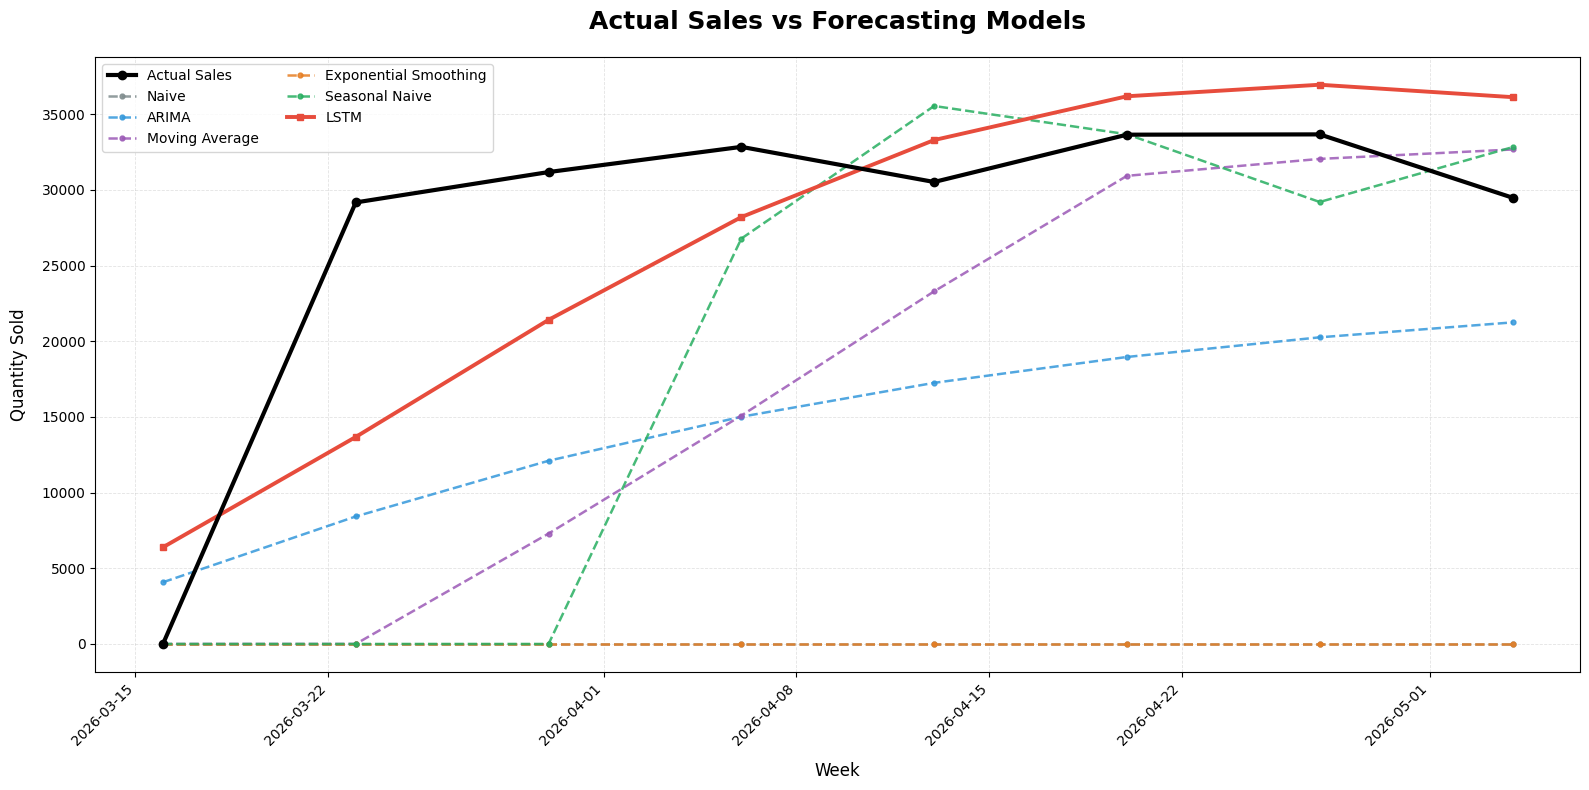

In [258]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 8))

# Actual sales
plt.plot(
    comparison.index,
    comparison["Actual"],
    label="Actual Sales",
    color="black",
    linewidth=3,
    marker="o",
    markersize=6,
    zorder=10
)

# Forecasting models
models = {
    "Naive": "#7F8C8D",
    "ARIMA": "#3498DB",
    "Moving Average": "#9B59B6",
    "Exponential Smoothing": "#E67E22",
    "Seasonal Naive": "#27AE60"
}

for model, color in models.items():
    plt.plot(
        comparison.index,
        comparison[model],
        label=model,
        color=color,
        linewidth=1.8,
        linestyle="--",
        marker=".",
        markersize=7,
        alpha=0.85
    )

# LSTM
plt.plot(
    comparison.index,
    comparison["LSTM"],
    label="LSTM",
    color="#E74C3C",
    linewidth=2.8,
    marker="s",
    markersize=5,
    zorder=9
)

# Titles and labels
plt.title(
    "Actual Sales vs Forecasting Models",
    fontsize=18,
    fontweight="bold",
    pad=20
)

plt.xlabel("Week", fontsize=12, labelpad=10)
plt.ylabel("Quantity Sold", fontsize=12, labelpad=10)

# Formatting
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.yticks(fontsize=10)

plt.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)

plt.legend(
    loc="best",
    fontsize=10,
    frameon=True,
    ncol=2
)

plt.tight_layout()
plt.show()

In [259]:
# Generate next 10 weeks
future_dates = pd.date_range(
    start=weekly.index.max() + pd.Timedelta(weeks=1),
    periods=10,
    freq="W-MON"
)

# Take the last 52 observations
last_sequence = scaler.transform(
    weekly.values.reshape(-1, 1)
)[-52:].reshape(1, 52, 1)

predictions_lstm = []

# Recursive forecasting
for i in range(10):

    prediction = model_lstm.predict(last_sequence, verbose=0)

    predictions_lstm.append(prediction[0, 0])

    # Add prediction to sequence and remove oldest observation
    last_sequence = np.append(
        last_sequence[:, 1:, :],
        prediction.reshape(1, 1, 1),
        axis=1
    )

# Convert predictions back to original scale
forecast_values = scaler.inverse_transform(
    np.array(predictions_lstm).reshape(-1, 1)
).flatten()

In [260]:
forecast_df = pd.DataFrame({
    "Forecast_Date": future_dates,
    "LSTM_Forecast": forecast_values
})

display(forecast_df.round(2))

C:\Users\Laptop\AppData\Local\Temp\ipykernel_28264\4263728415.py:6: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast_df.round(2))


,Forecast_Date,LSTM_Forecast
0,2026-05-11,28930.029297
1,2026-05-18,28443.599609
2,2026-05-25,28543.000000
3,2026-06-01,28838.400391
4,2026-06-08,29117.810547
5,2026-06-15,29271.210938
6,2026-06-22,29268.910156
7,2026-06-29,29134.490234
8,2026-07-06,28917.240234
9,2026-07-13,28669.970703


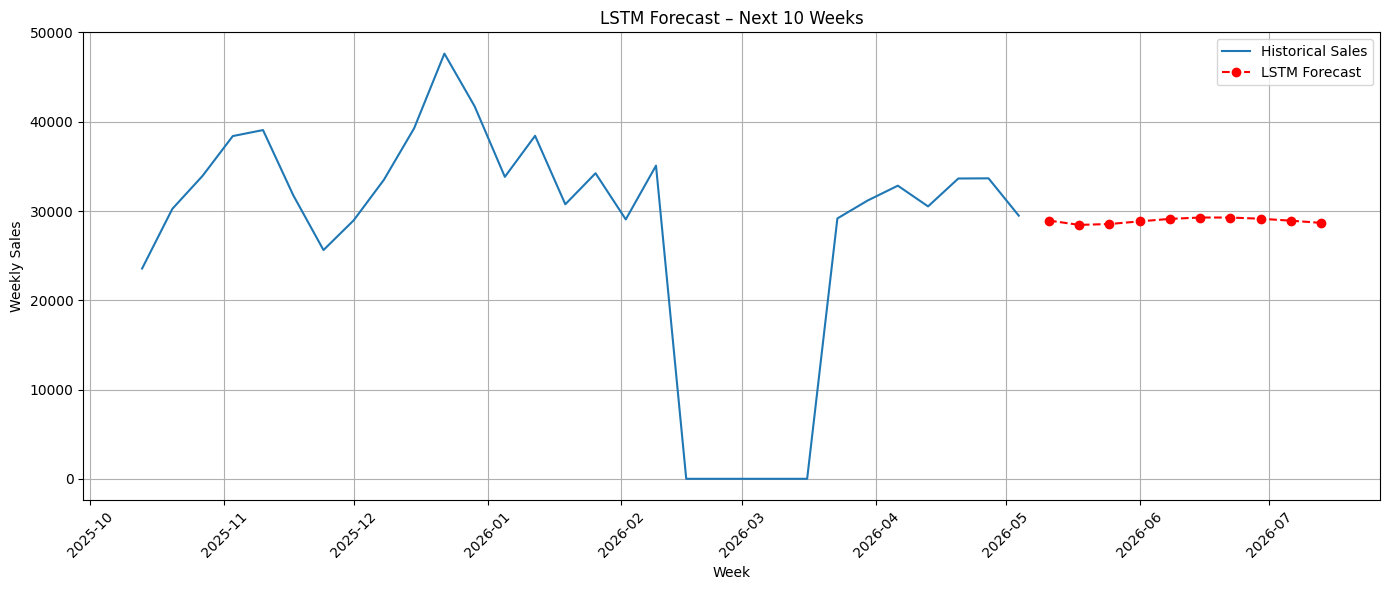

In [261]:
plt.figure(figsize=(14, 6))

plt.plot(
    weekly.index[-30:],
    weekly.iloc[-30:],
    label="Historical Sales"
)

plt.plot(
    future_dates,
    forecast_values,
    marker="o",
    linestyle="--",
    label="LSTM Forecast",
    color="red"
)

plt.title("LSTM Forecast – Next 10 Weeks")
plt.xlabel("Week")
plt.ylabel("Weekly Sales")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

## Interactive Visualisations

[📊 Explore Weekly Article Sales](https://achrafmss12.github.io/retail_2026/weekly_sales.html)

[📈 Explore Sales by Hour and Weekday](https://achrafmss12.github.io/retail_2026/index.html)